# Part 2: A&E 4-hour breach analysis and prediction
A random sample of 400 patients is used for descriptive analysis, and the full dataset for a class-weighted logistic regression that predicts 4-hour breaches at arrival.

Requires `AED4weeks.csv` (coursework data, not included) in the same folder.

## Load and sample data

In [1]:
import pandas as pd

df=pd.read_csv('AED4weeks.csv')
# 1. to make sure that breachornot is string and transform to lowwer case
df['Breachornot'] = df['Breachornot'].astype(str).str.strip().str.lower()

# 2. transform to 0 and 1
mapping = {'non-breach': 0, 'breach': 1}
df['Breachornot'] = df['Breachornot'].map(mapping)

# 3. check the results (to confrim is there a NaN or not)
print(df['Breachornot'].value_counts(dropna=False))

#random choose 400 sample
sample_df = df.sample(n=400, random_state=73701)

Breachornot
0    8522
1     259
Name: count, dtype: int64


## Descriptive statistics

/tmp/ipykernel_179/3875273333.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='DayofWeek', data=sample_df, order=dow_order, palette='viridis')
/tmp/ipykernel_179/3875273333.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_hrg.values, y=top_hrg.index, palette='magma')


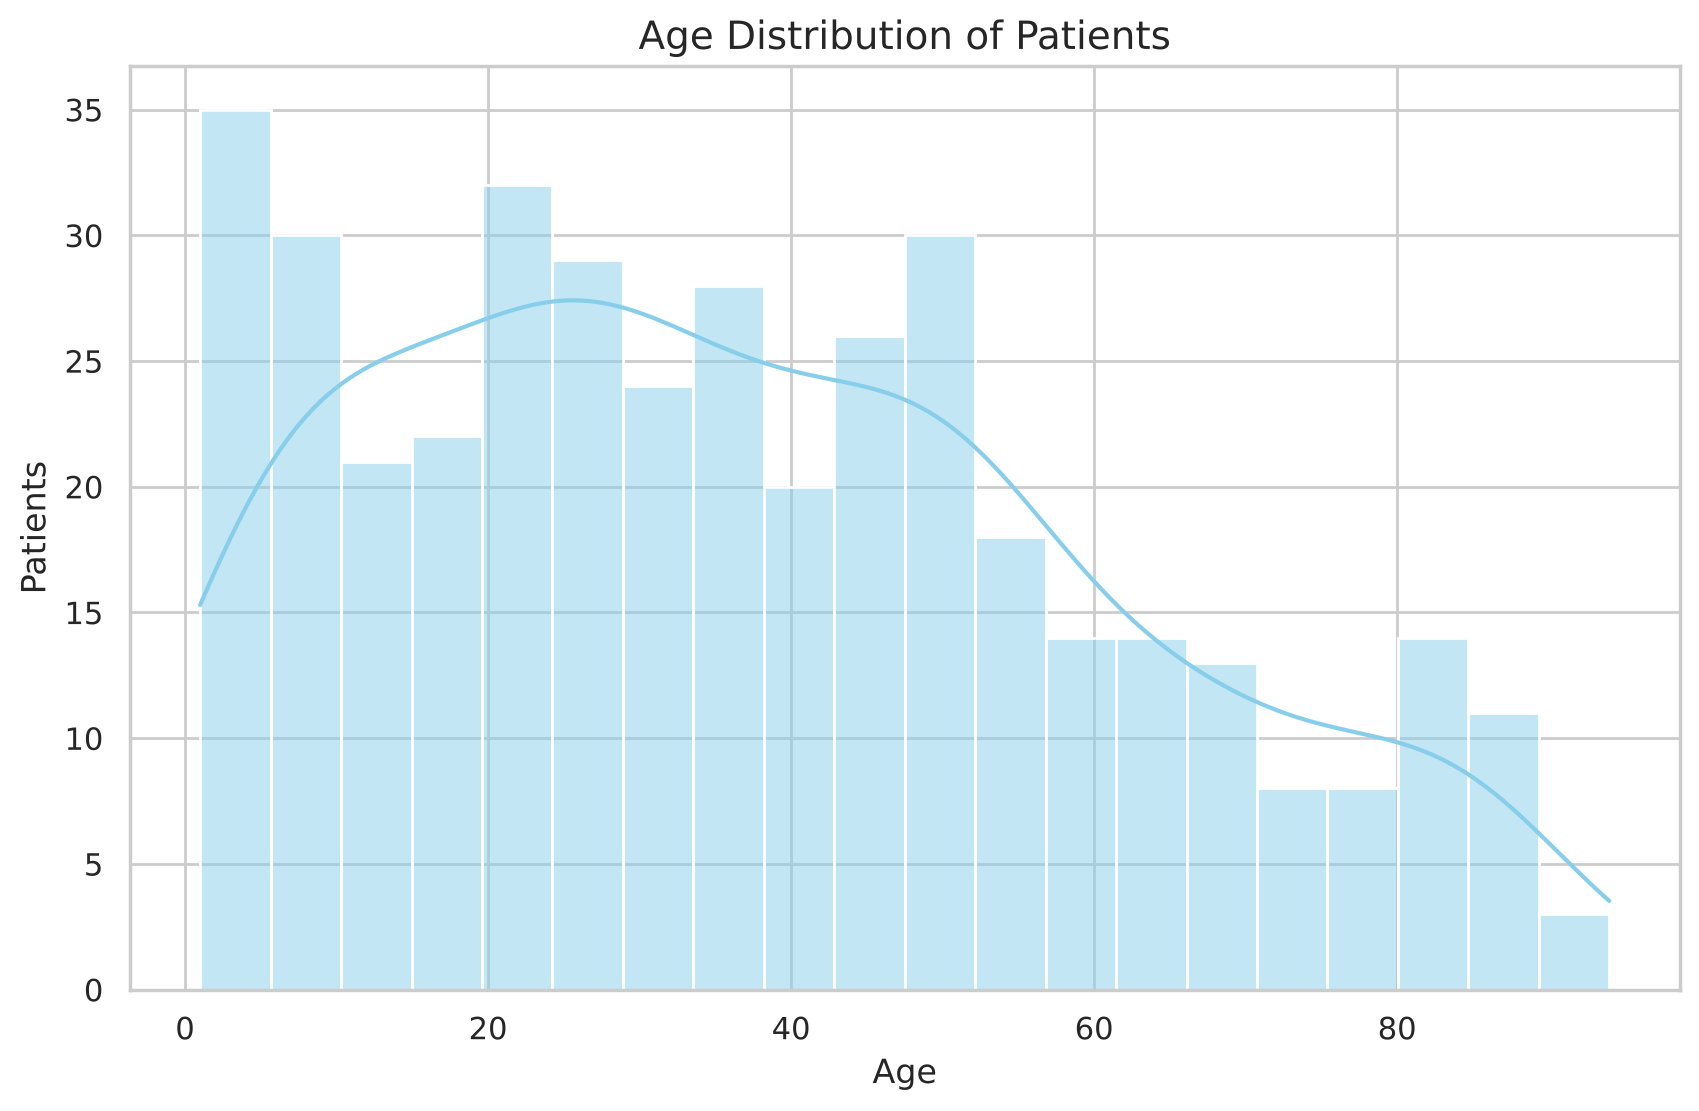

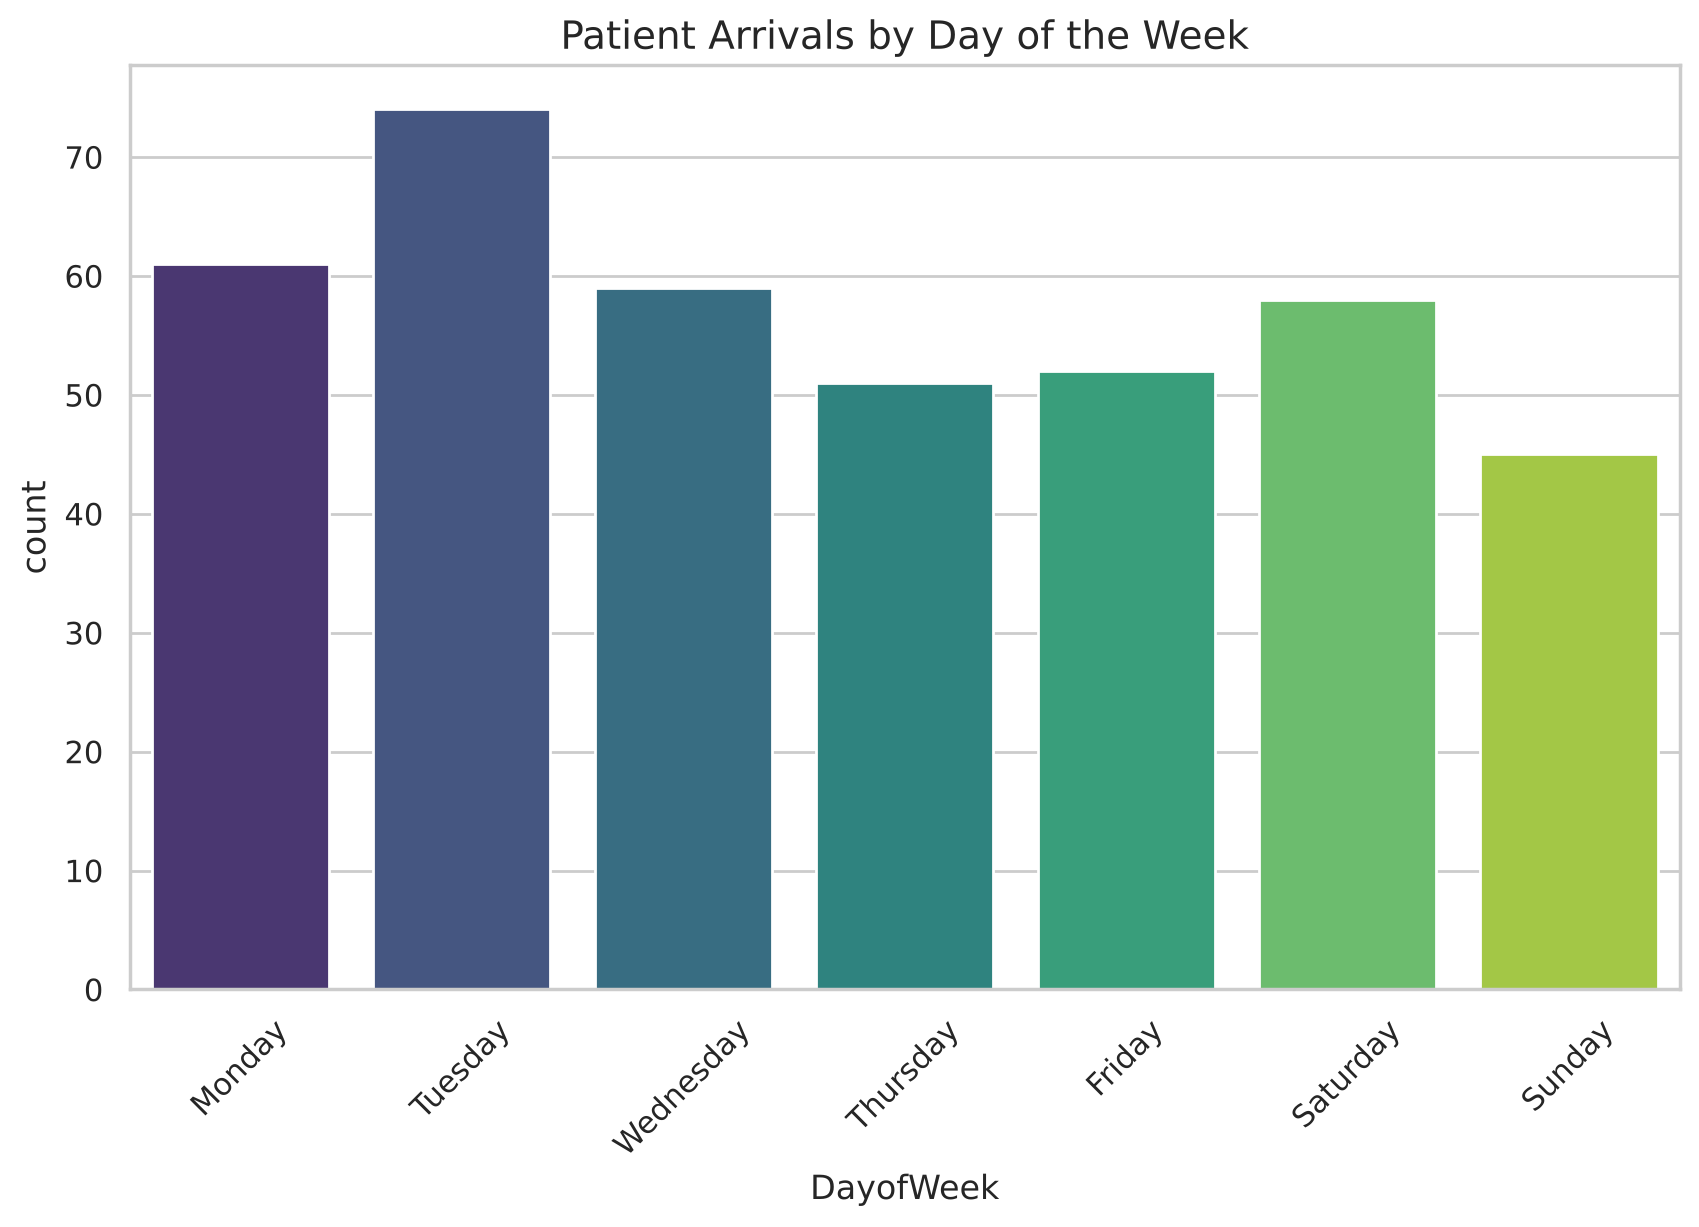

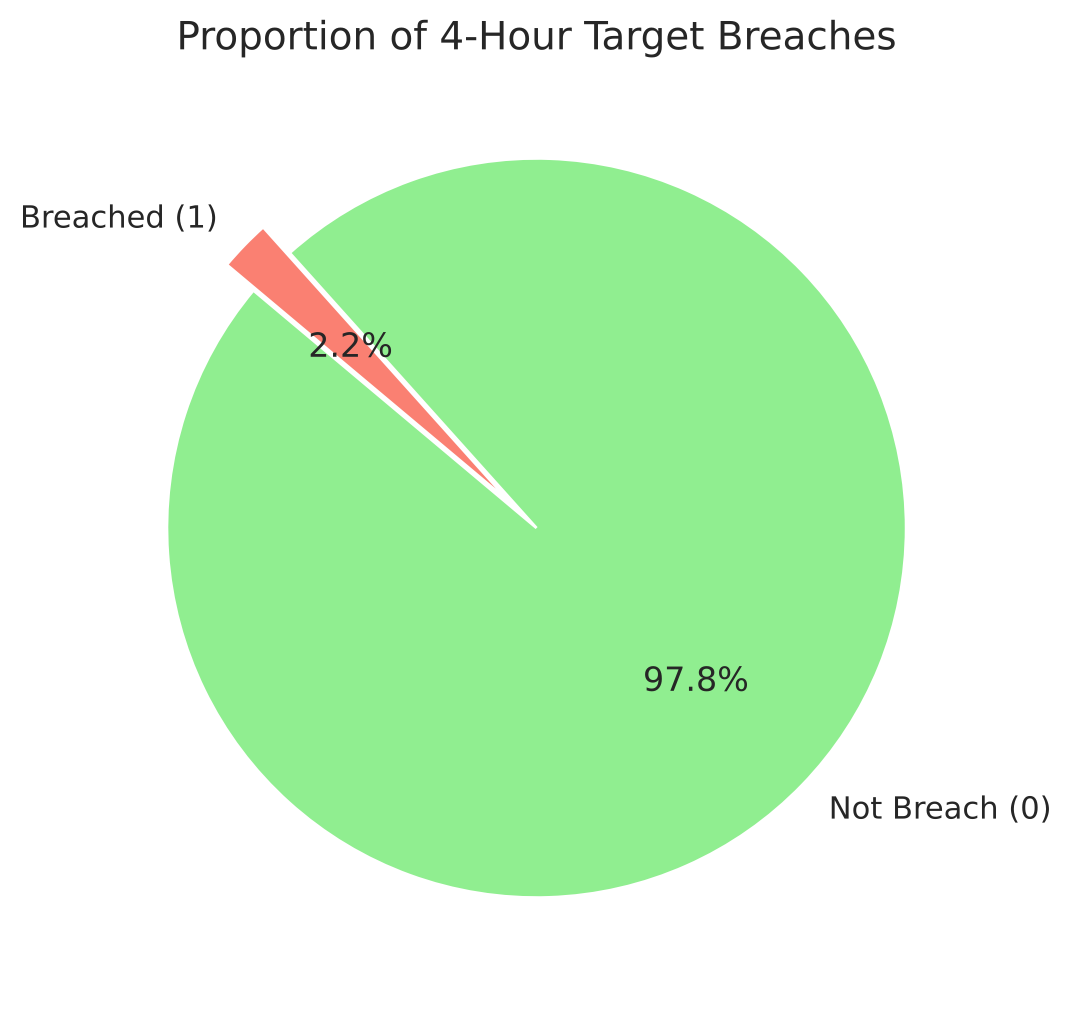

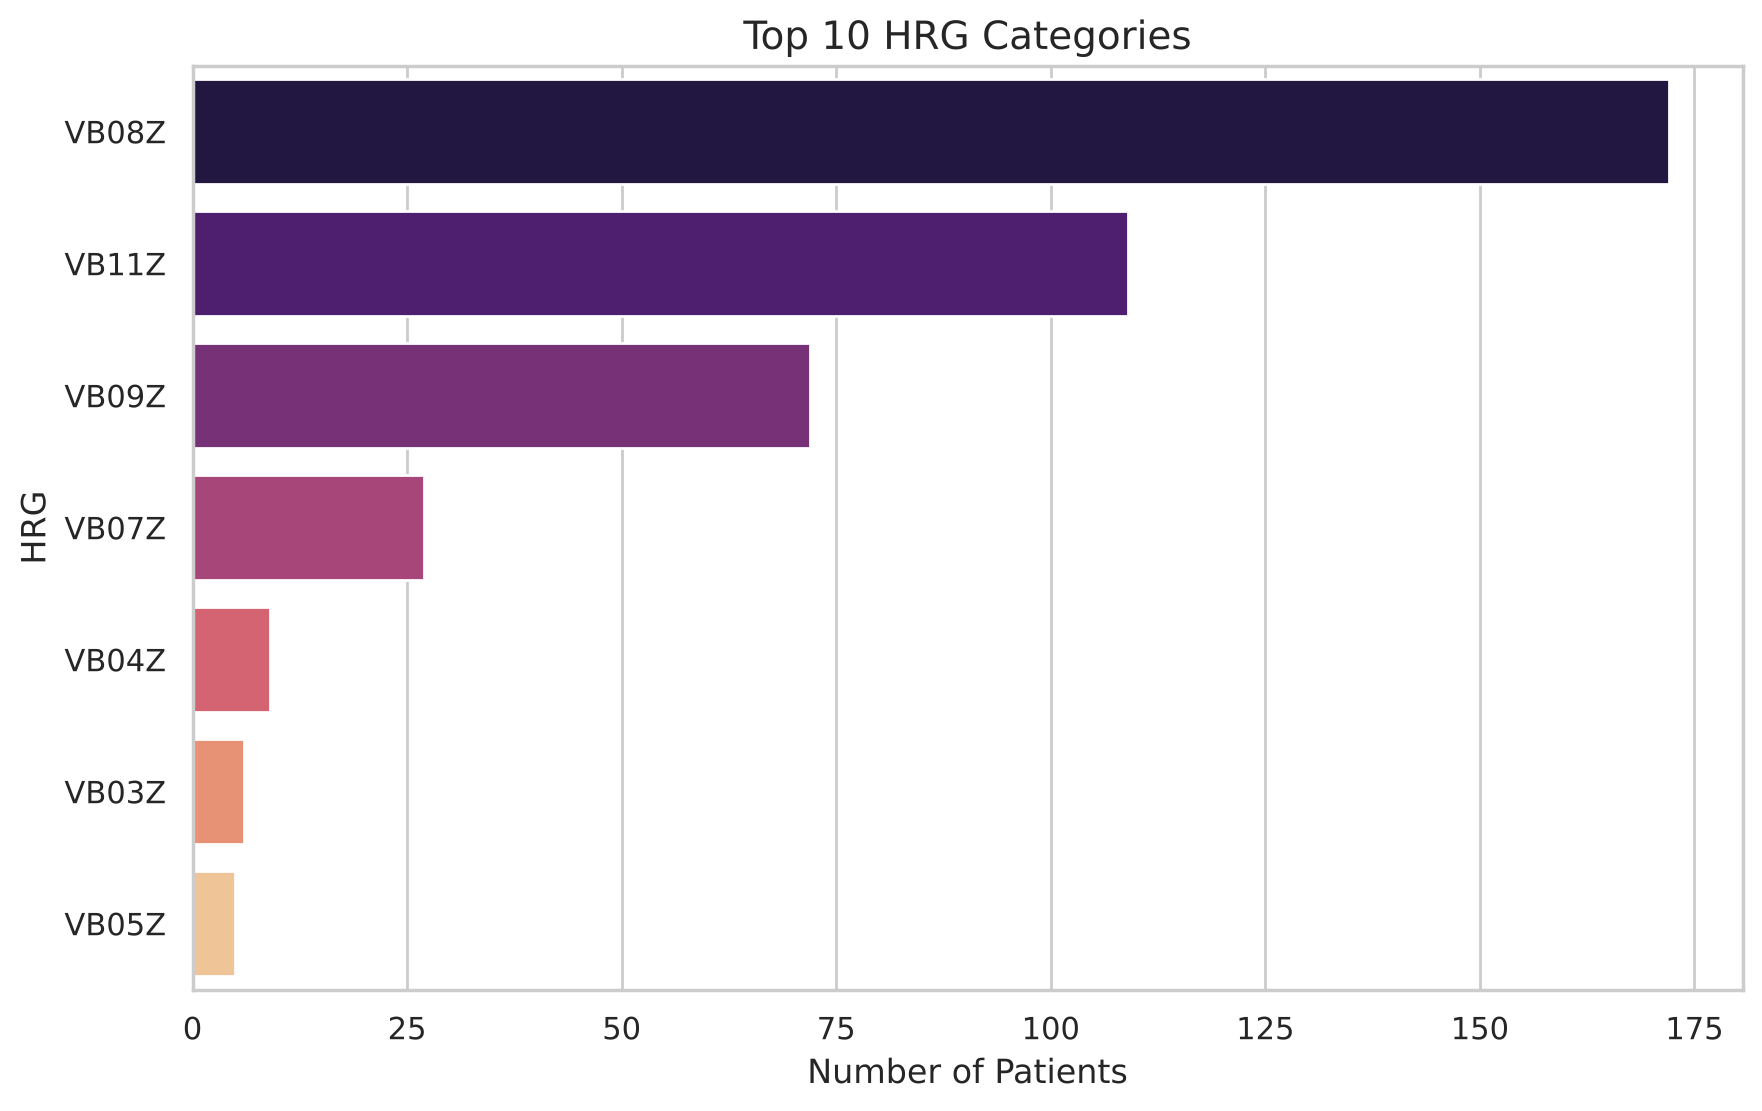

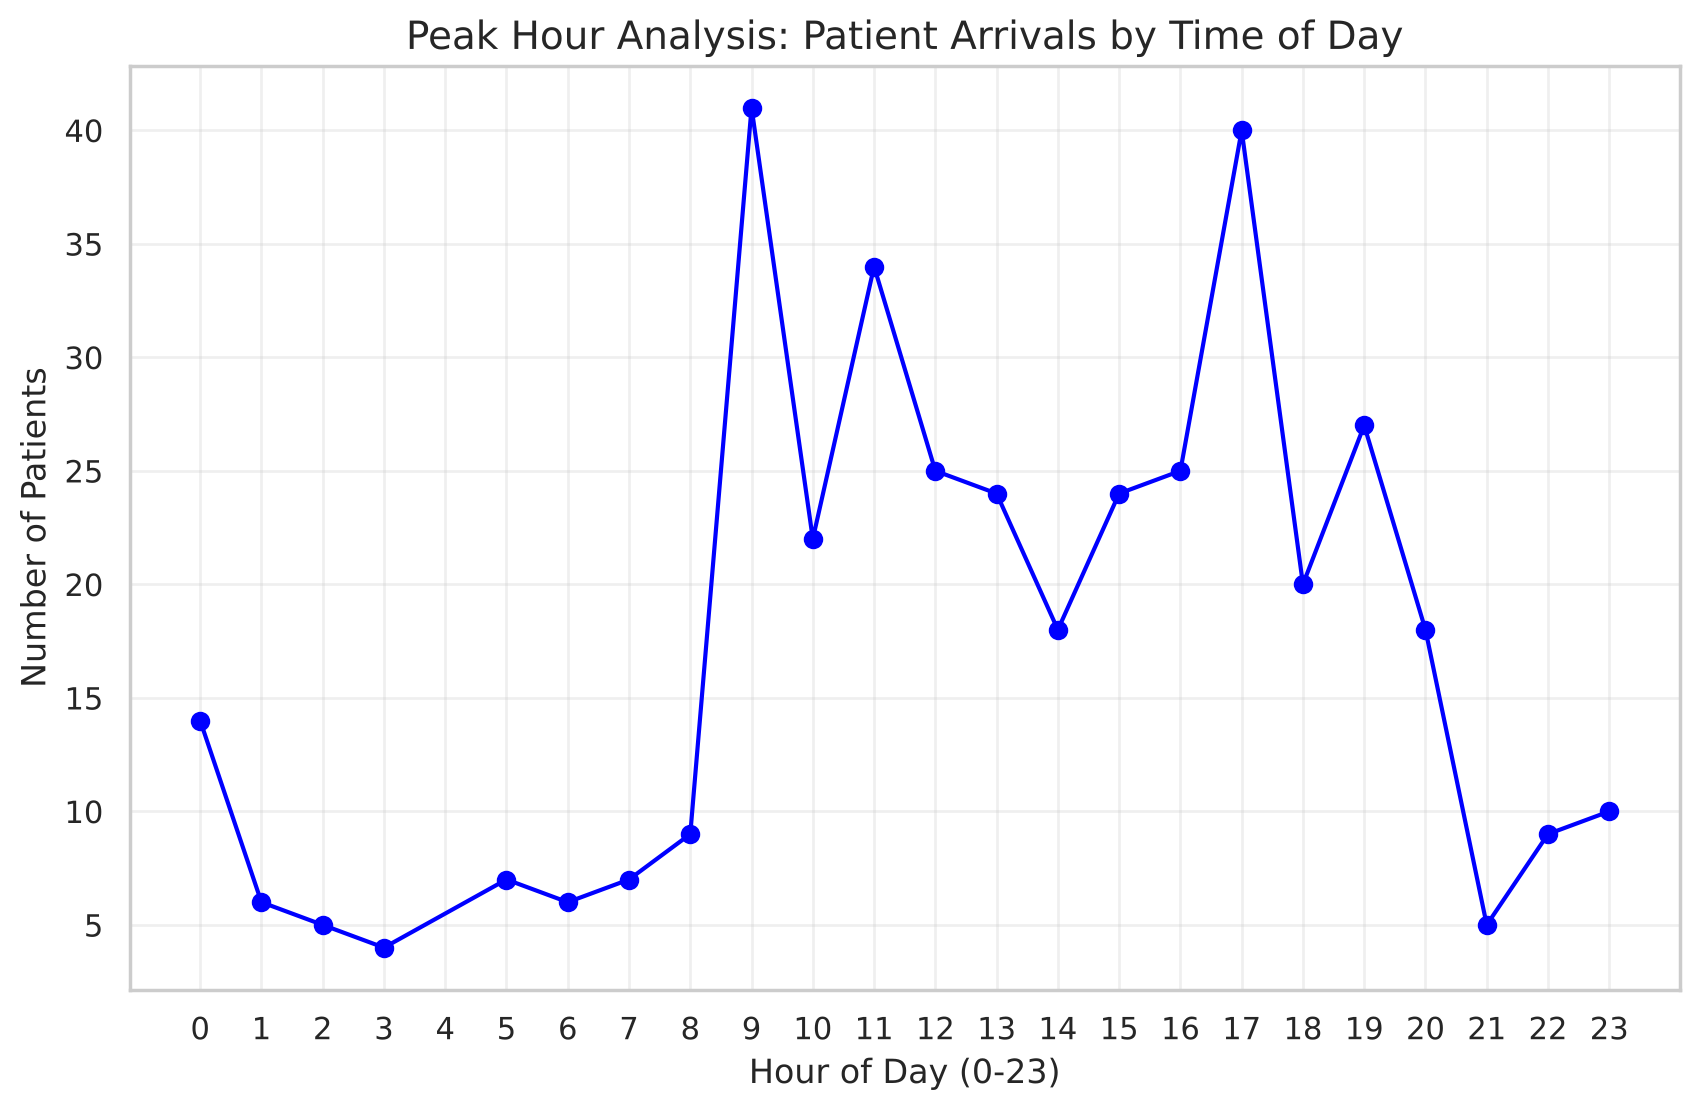

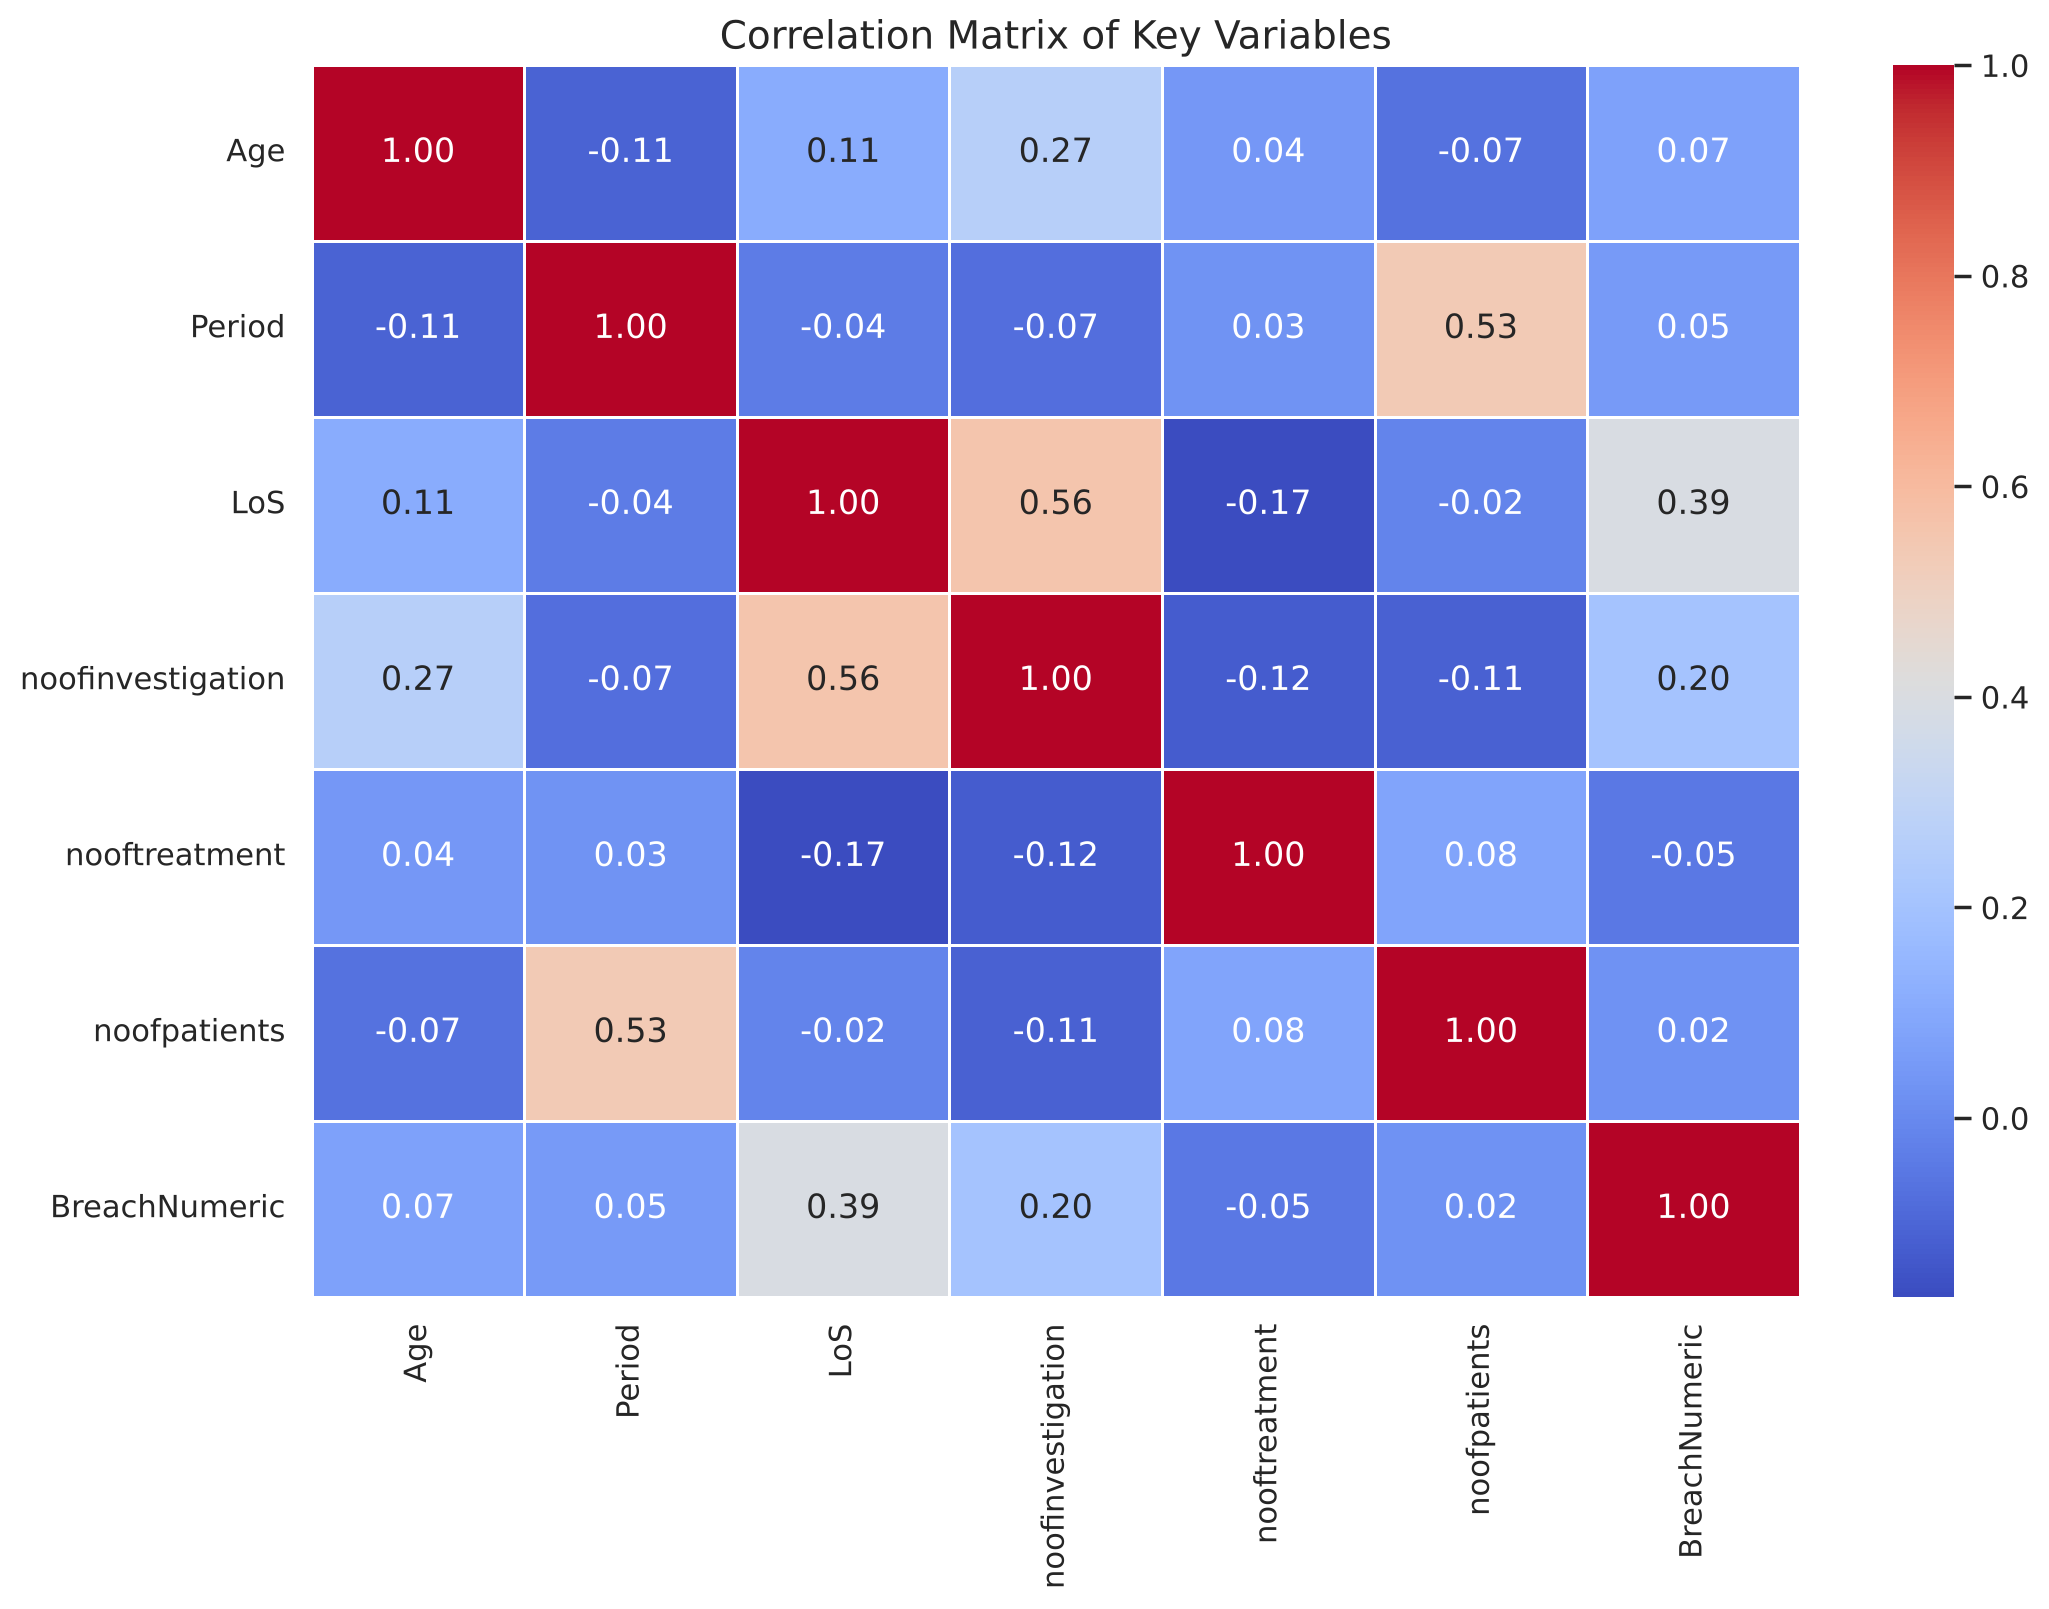

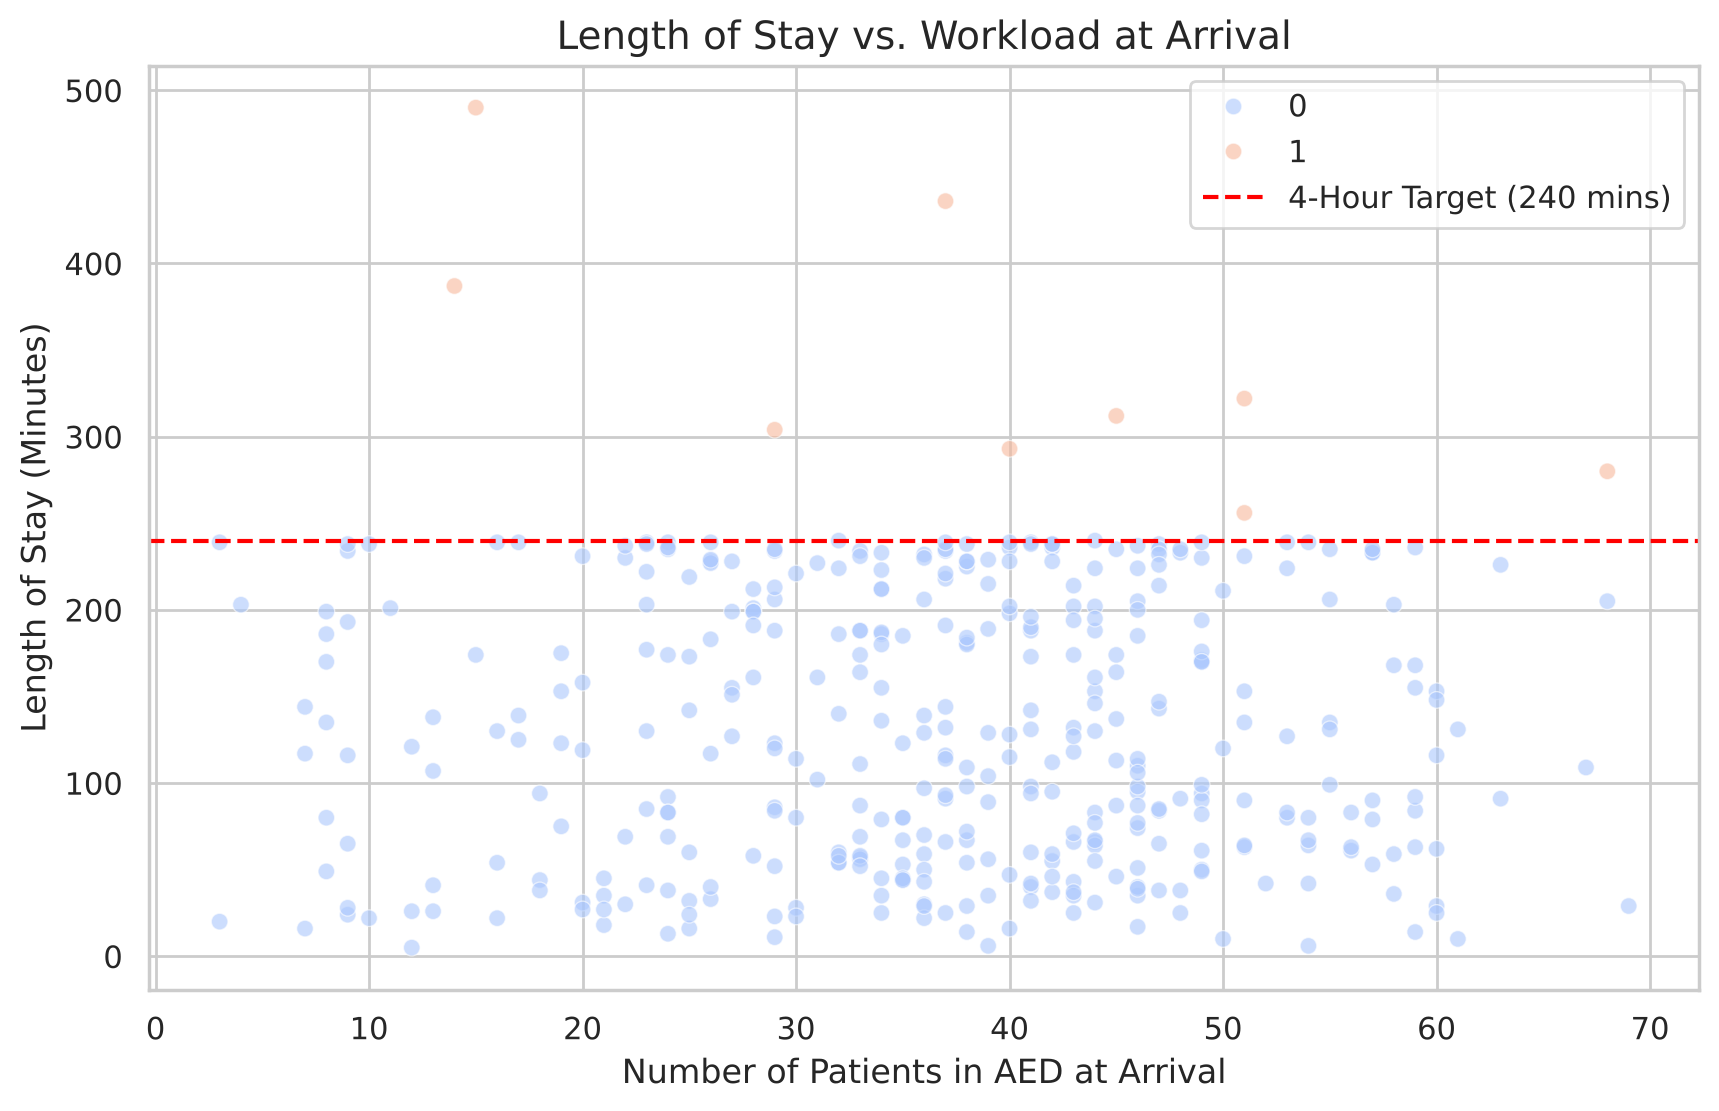

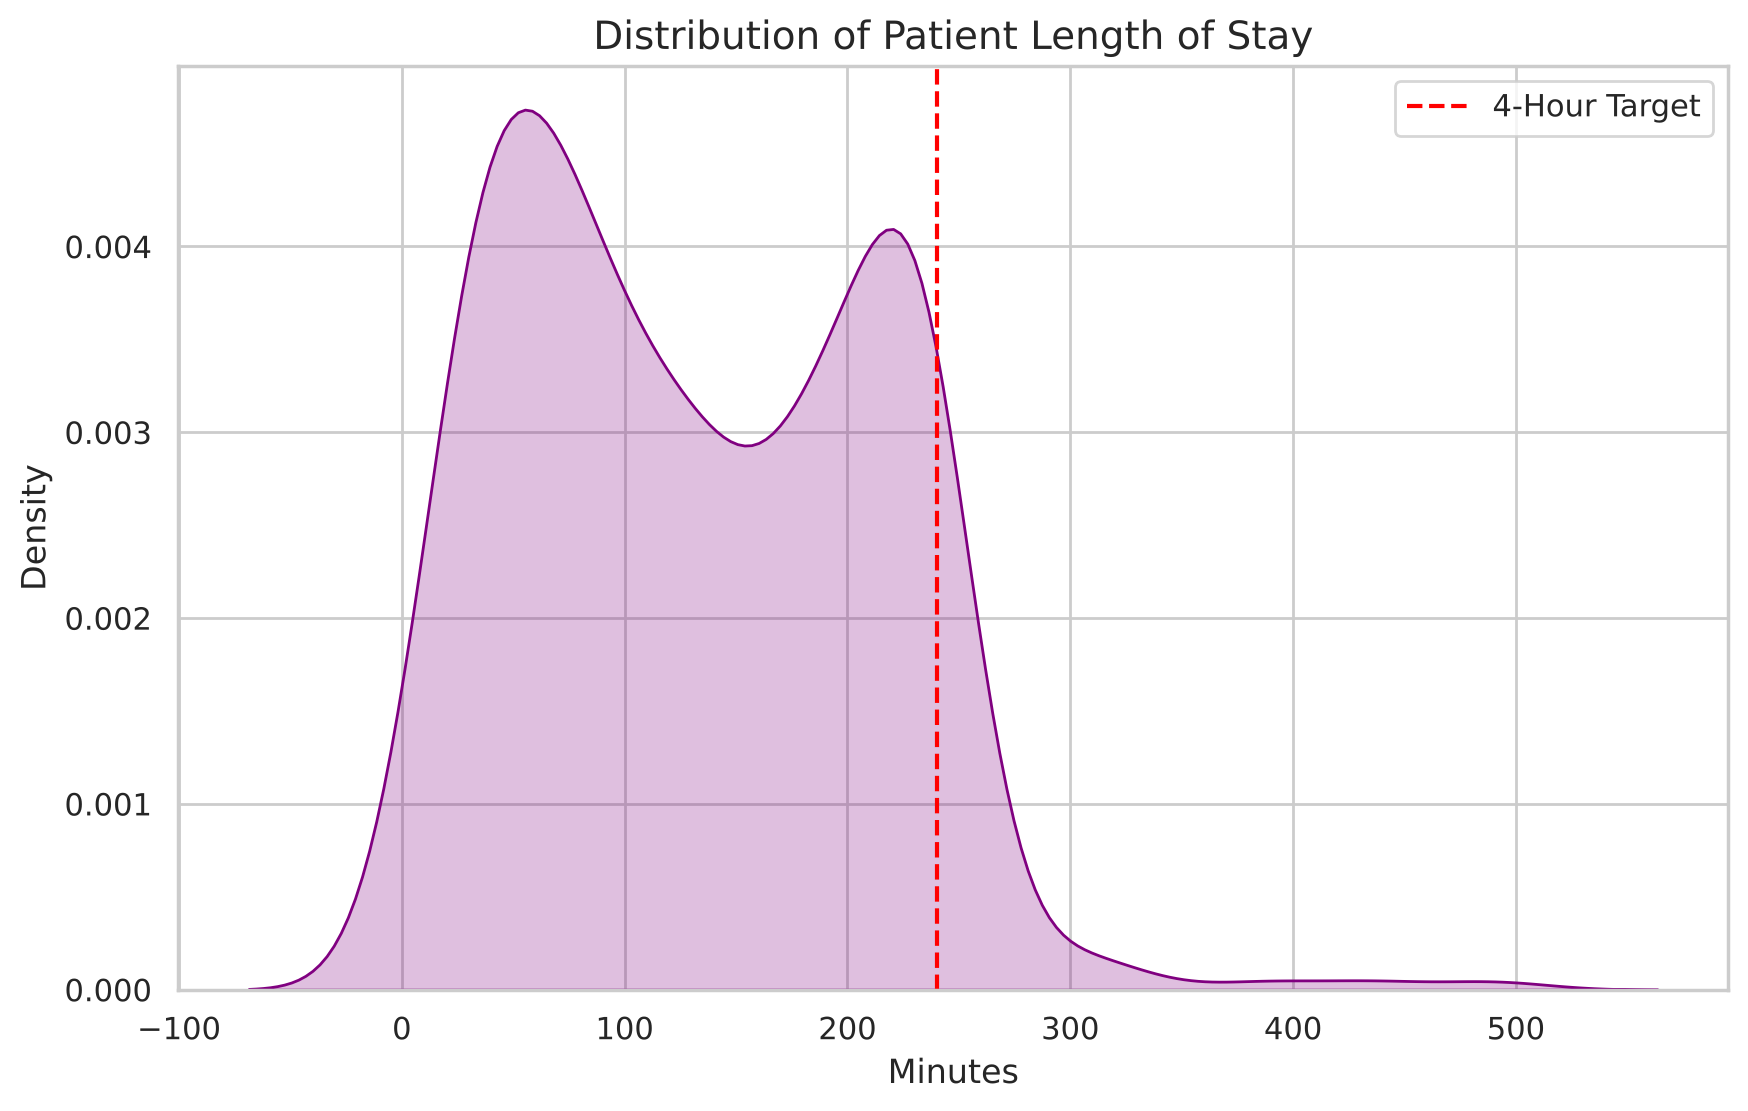

In [2]:
#task 4
import seaborn as sns
import matplotlib.pyplot as plt

# Set the theme for the plots
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Map 'Breachornot' to numeric values for analysis
# 'non-breach' becomes 0, 'breach' becomes 1. Also handles existing 0/1 values.
mapping = {'non-breach': 0, 'breach': 1, 0: 0, 1: 1}
sample_df['BreachNumeric'] = sample_df['Breachornot'].map(mapping)

# 1. Bar Chart for Age Distribution
plt.figure()
sns.histplot(sample_df['Age'], bins=20, kde=True, color='skyblue')
plt.title('Age Distribution of Patients', fontsize=14)
plt.xlabel('Age')
plt.ylabel('Patients')
#plt.savefig('age_distribution.png')

# 2. Bar Chart Day of Week Distribution
plt.figure()
# Ensure the days of the week are in the correct order
dow_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
sns.countplot(x='DayofWeek', data=sample_df, order=dow_order, palette='viridis')
plt.title('Patient Arrivals by Day of the Week', fontsize=14)
plt.xticks(rotation=45)
#plt.savefig('dow_distribution.png')

# 3. Pie Chart for Breach Proportion
plt.figure()
breach_counts = sample_df['BreachNumeric'].value_counts()
plt.pie(breach_counts, labels=['Not Breach (0)', 'Breached (1)'], autopct='%1.1f%%', 
        colors=['lightgreen', 'salmon'], startangle=140, explode=(0, 0.1))
plt.title('Proportion of 4-Hour Target Breaches', fontsize=14)
#plt.savefig('breach_proportion.png')

# 4. Bar Chart HRG Category (Top 10)
plt.figure()
top_hrg = sample_df['HRG'].value_counts().nlargest(10)
sns.barplot(x=top_hrg.values, y=top_hrg.index, palette='magma')
plt.title('Top 10 HRG Categories', fontsize=14)
plt.xlabel('Number of Patients')
#plt.savefig('hrg_top10.png')

# 5. Linear Graph Peak Hour Analysis (Arrivals by Period)
plt.figure()
peak_hours = sample_df.groupby('Period').size()
plt.plot(peak_hours.index, peak_hours.values, marker='o', linestyle='-', color='blue')
plt.title('Peak Hour Analysis: Patient Arrivals by Time of Day', fontsize=14)
plt.xlabel('Hour of Day (0-23)')
plt.ylabel('Number of Patients')
plt.xticks(range(0, 24))
plt.grid(True, alpha=0.3)
#plt.savefig('peak_hour_analysis.png')

# 6. Correlation Matrix
plt.figure(figsize=(12, 8))
# Select only numeric columns for correlation analysis
numeric_cols = ['Age', 'Period', 'LoS', 'noofinvestigation', 'nooftreatment', 'noofpatients', 'BreachNumeric']
corr = sample_df[numeric_cols].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix of Key Variables', fontsize=14)
#plt.savefig('correlation_matrix.png')

# 7. Length of Stay (LoS) vs Workload at Arrival
plt.figure()
sns.scatterplot(x='noofpatients', y='LoS', hue='BreachNumeric', data=sample_df, palette='coolwarm', alpha=0.6)
plt.axhline(y=240, color='red', linestyle='--', label='4-Hour Target (240 mins)')
plt.title('Length of Stay vs. Workload at Arrival', fontsize=14)
plt.xlabel('Number of Patients in AED at Arrival')
plt.ylabel('Length of Stay (Minutes)')
plt.legend()
#plt.savefig('los_vs_workload.png')

# 8. Distribution of Length of Stay
plt.figure()
sns.kdeplot(sample_df['LoS'], fill=True, color='purple')
plt.axvline(x=240, color='red', linestyle='--', label='4-Hour Target')
plt.title('Distribution of Patient Length of Stay', fontsize=14)
plt.xlabel('Minutes')
plt.ylabel('Density')
plt.legend()
#plt.savefig('los_distribution.png')

## Breach factor analysis

/tmp/ipykernel_179/1521031253.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Breachornot', y='LoS', data=sample_df, palette="Set2")
/tmp/ipykernel_179/1521031253.py:49: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=age_trend.index, y=age_trend.values, palette="Blues_d")


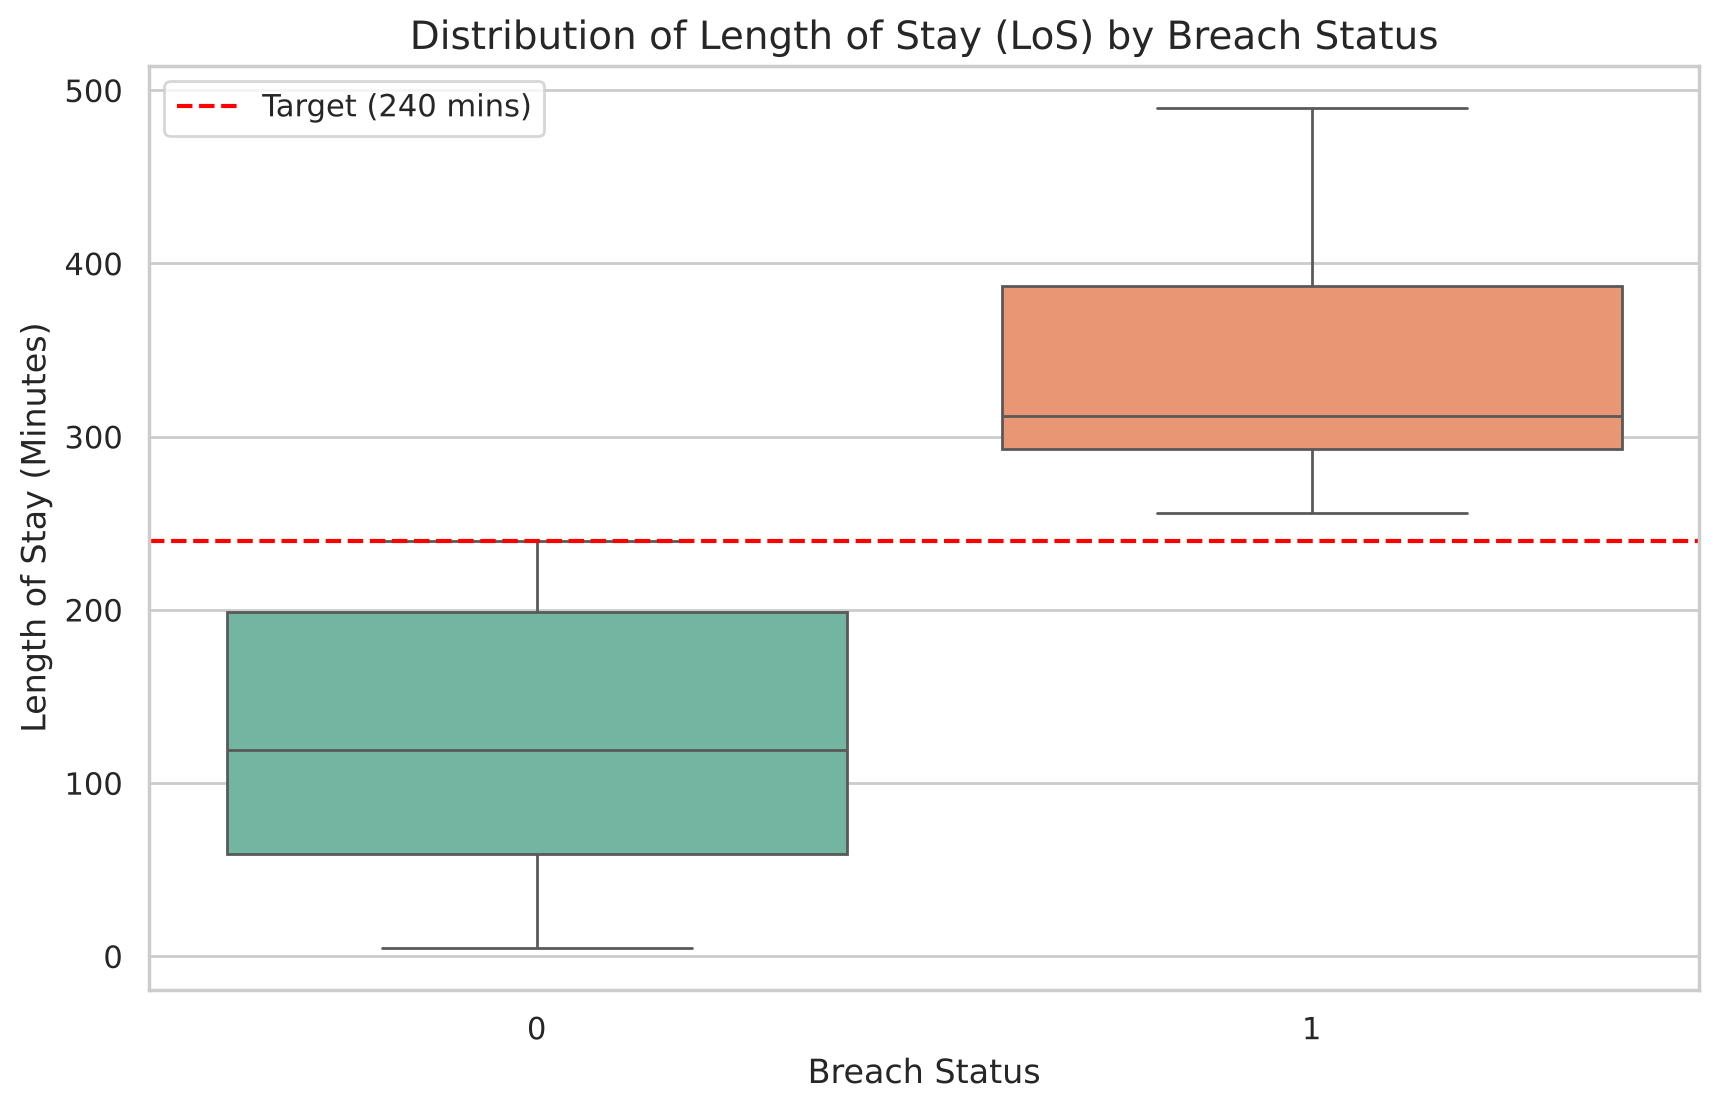

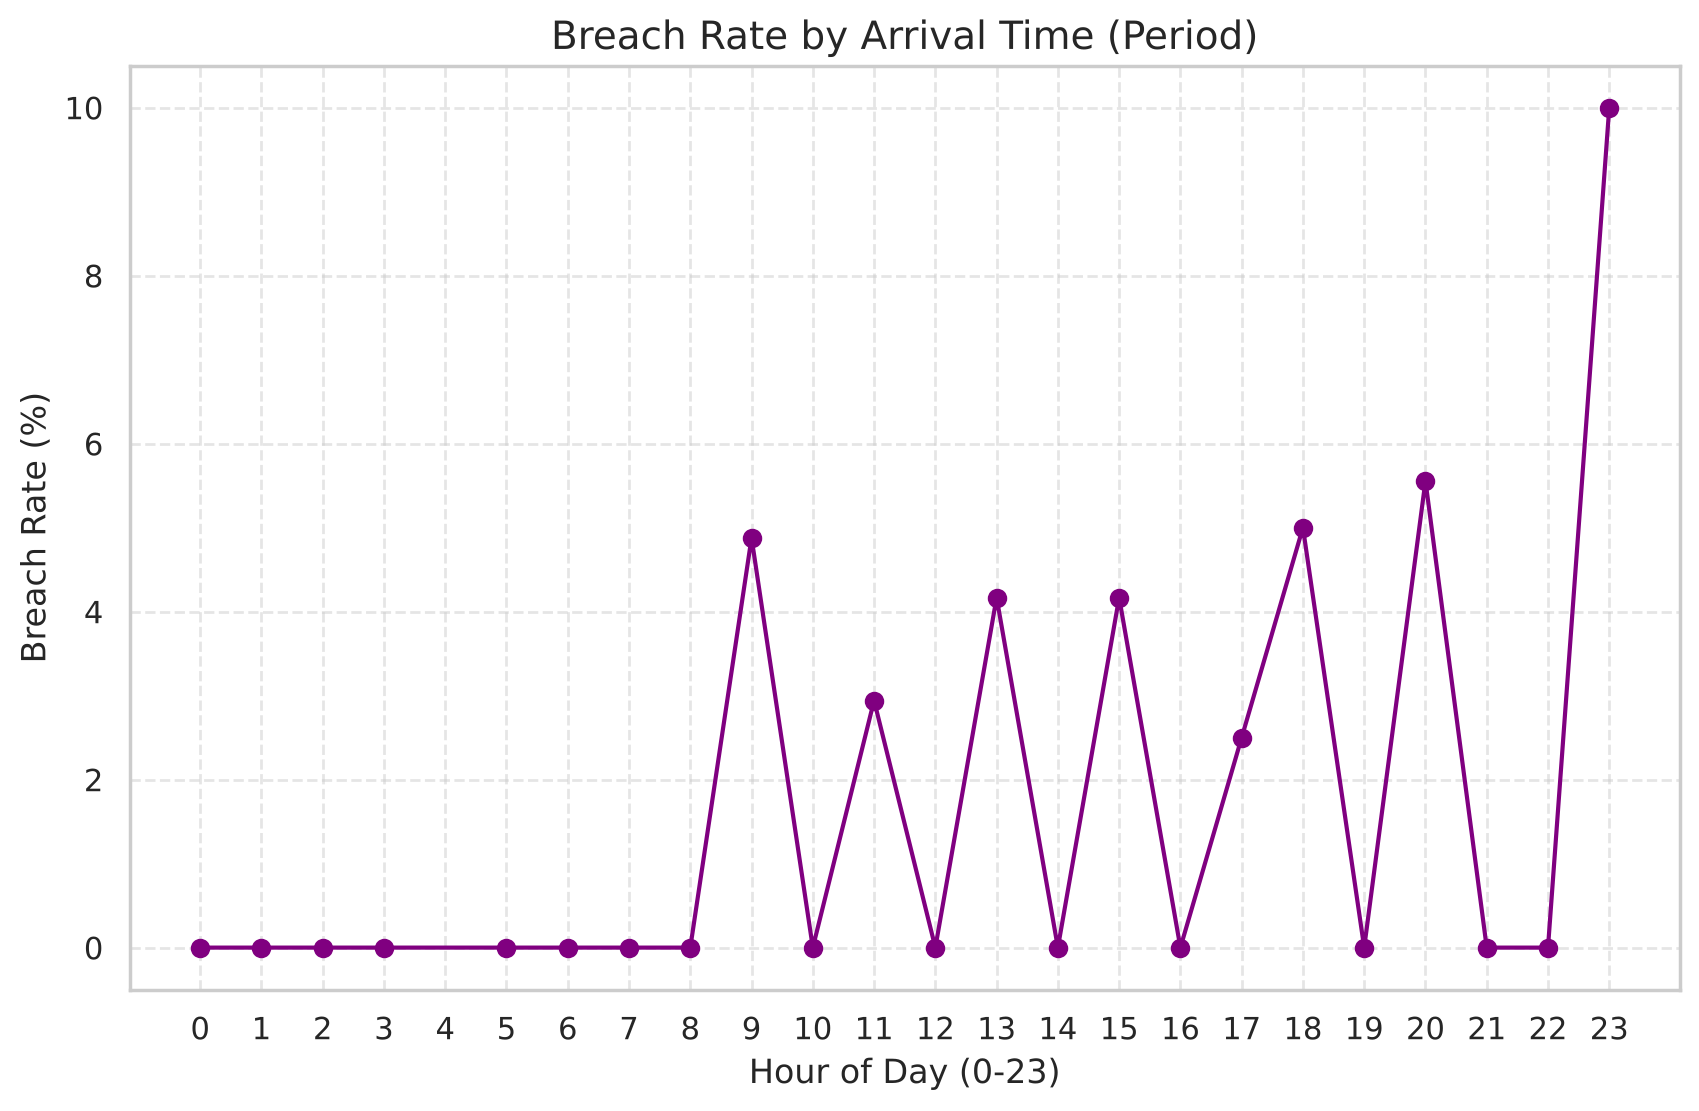

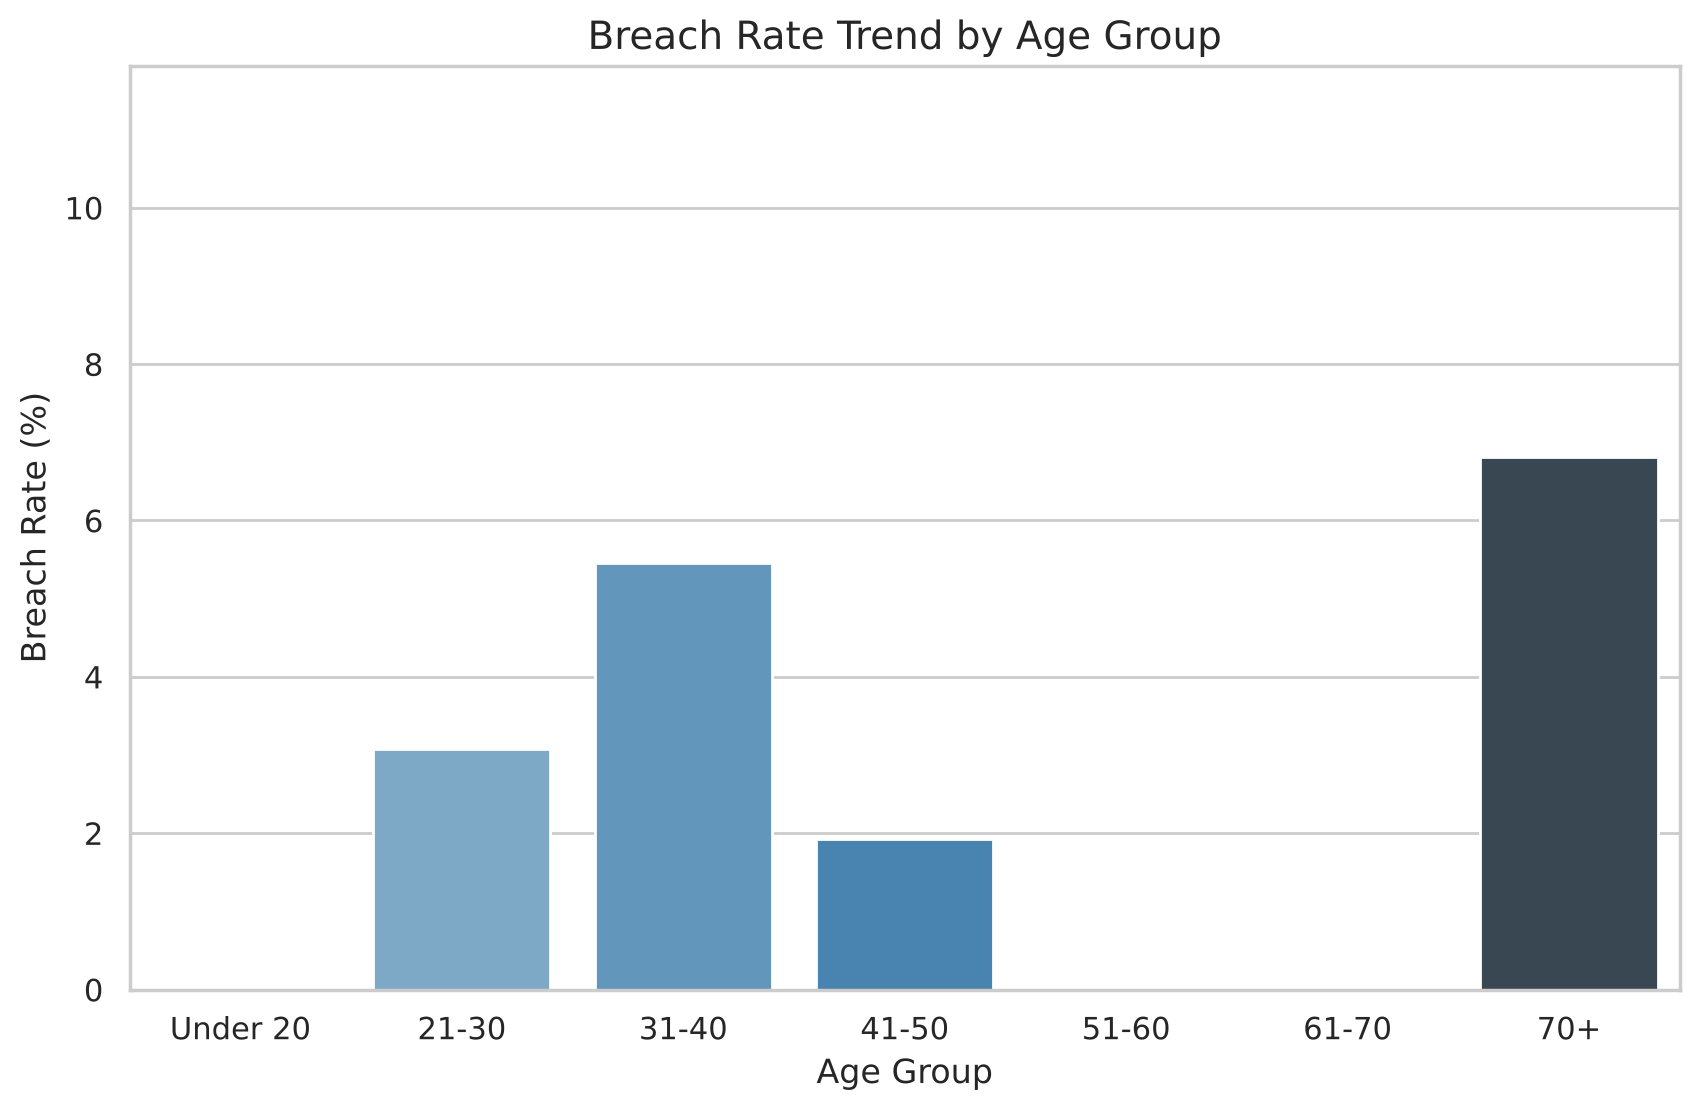

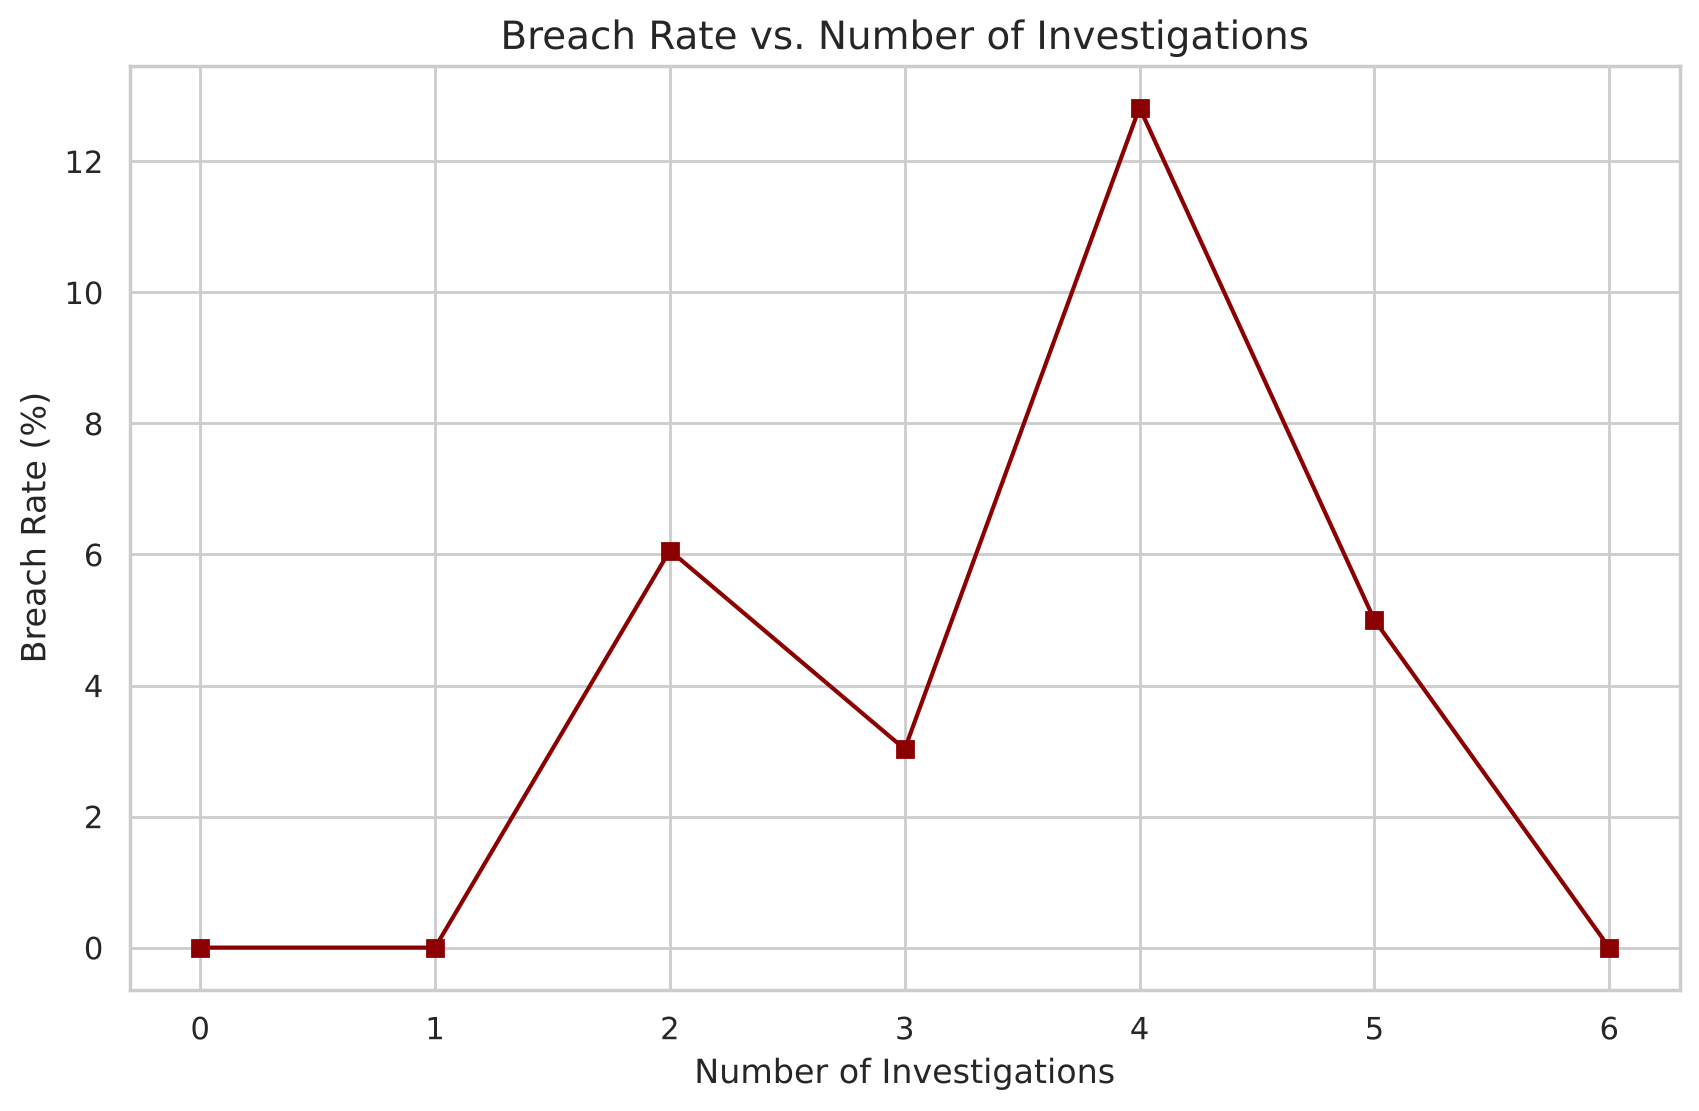

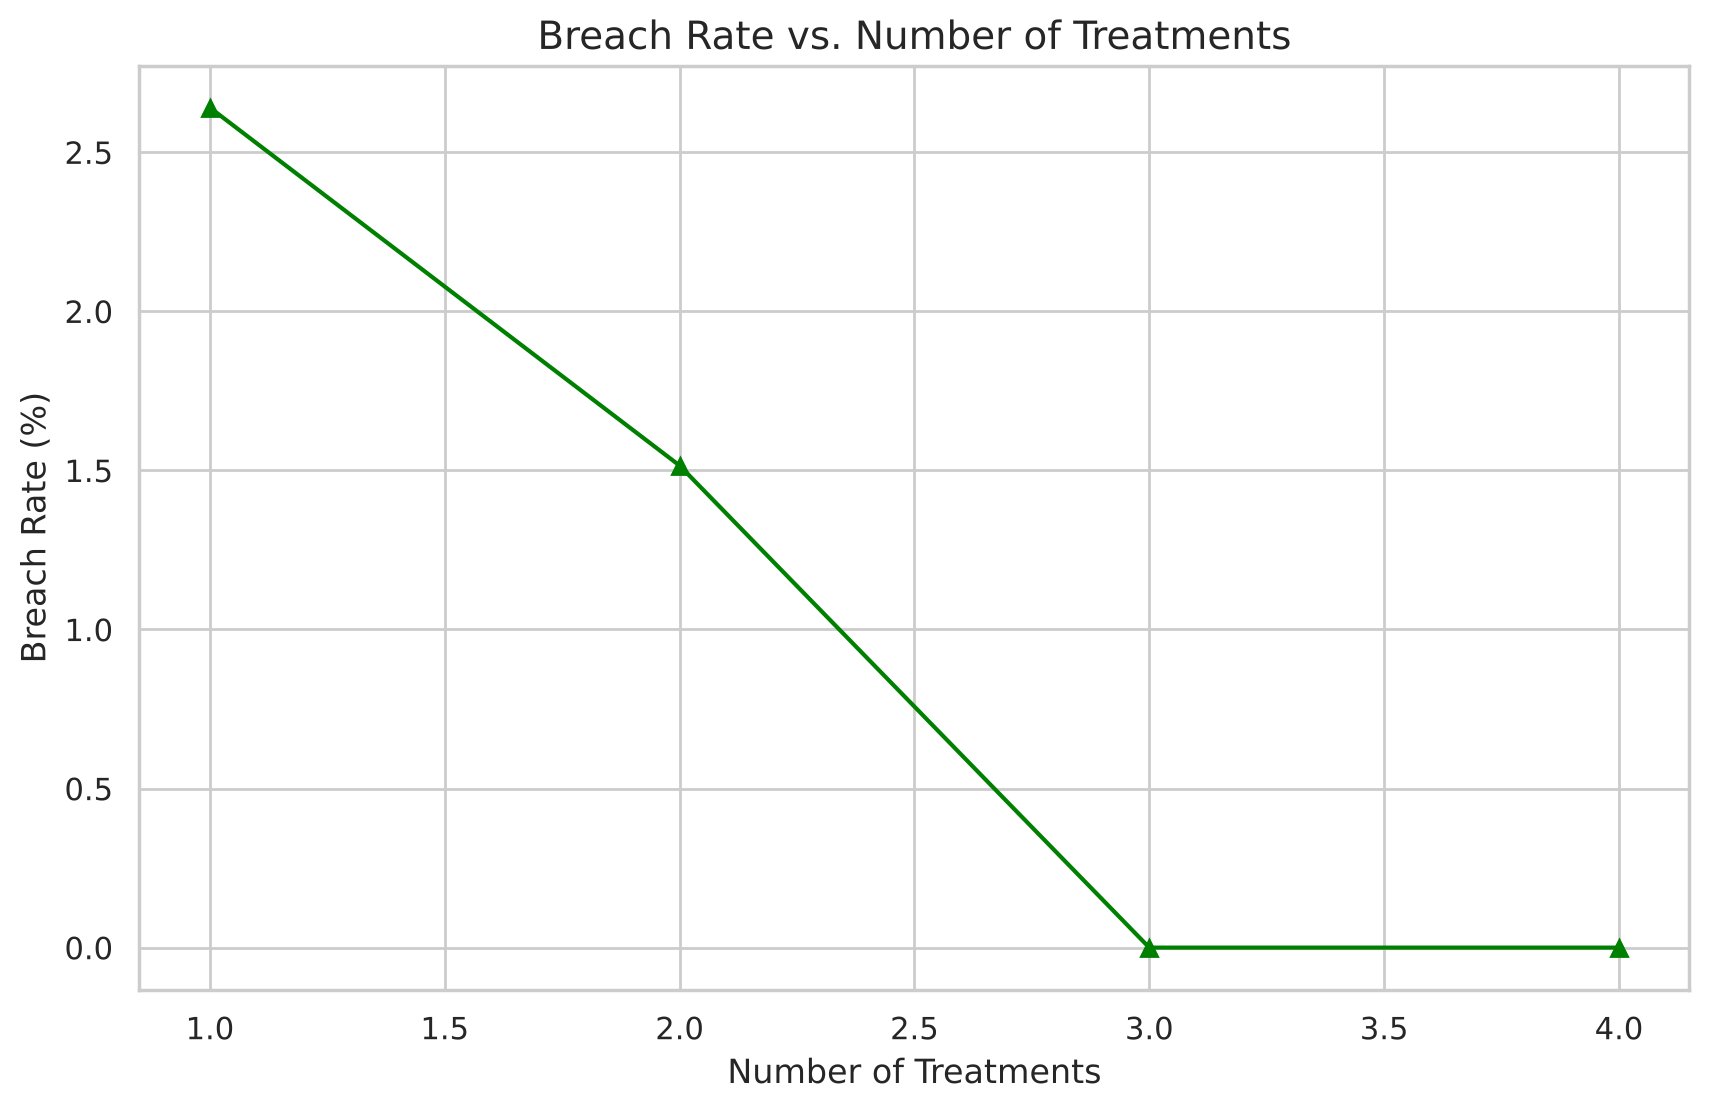

In [3]:
#task 5
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



# --- Data Preprocessing for Task 5 ---
# Ensure 'Breachornot' is mapped to numeric (0 and 1) for rate calculations
# 0 = Met Target, 1 = Breached Target
mapping = {'non-breach': 0, 'breach': 1, 0: 0, 1: 1}
sample_df['BreachNumeric'] = sample_df['Breachornot'].map(mapping)

# Create Age Groups if not already present
age_bins = [0, 20, 30, 40, 50, 60, 70, 120]
age_labels = ['Under 20', '21-30', '31-40', '41-50', '51-60', '61-70', '70+']
sample_df['AgeGroup'] = pd.cut(sample_df['Age'], bins=age_bins, labels=age_labels)

# 1. Boxplots of Length of Stay (LoS) by Breach Status
plt.figure()
sns.boxplot(x='Breachornot', y='LoS', data=sample_df, palette="Set2")
plt.axhline(y=240, color='red', linestyle='--', label='Target (240 mins)')
plt.title('Distribution of Length of Stay (LoS) by Breach Status', fontsize=14)
plt.xlabel('Breach Status')
plt.ylabel('Length of Stay (Minutes)')
plt.legend()
#plt.savefig('task5_boxplot_los.png')


# 2. Breach Rate by Arrival Period (Hour of Day)
# Calculate the percentage of breaches for each hour of the day
period_breach = sample_df.groupby('Period')['BreachNumeric'].mean() * 100

plt.figure()
plt.plot(period_breach.index, period_breach.values, marker='o', linestyle='-', color='purple')
plt.title('Breach Rate by Arrival Time (Period)', fontsize=14)
plt.xlabel('Hour of Day (0-23)')
plt.ylabel('Breach Rate (%)')
plt.xticks(range(0, 24))
plt.grid(True, linestyle='--', alpha=0.5)
#plt.savefig('task5_breach_rate_period.png')

# 3. Breach Rate Trend by Age Group
# Calculate breach rate per age group
# observed=True is used to handle categorical data efficiently in newer pandas versions
age_trend = sample_df.groupby('AgeGroup', observed=True)['BreachNumeric'].mean() * 100

plt.figure()
sns.barplot(x=age_trend.index, y=age_trend.values, palette="Blues_d")
plt.title('Breach Rate Trend by Age Group', fontsize=14)
plt.xlabel('Age Group')
plt.ylabel('Breach Rate (%)')
plt.ylim(0, max(age_trend.values) + 5) # Add space for labels
#plt.savefig('task5_breach_rate_age.png')

# 4. Breach Rate Trend by Number of Investigations
# Check how the number of diagnostic tests impacts the probability of breaching
invest_trend = sample_df.groupby('noofinvestigation')['BreachNumeric'].mean() * 100

plt.figure()
plt.plot(invest_trend.index, invest_trend.values, marker='s', linestyle='-', color='darkred')
plt.title('Breach Rate vs. Number of Investigations', fontsize=14)
plt.xlabel('Number of Investigations')
plt.ylabel('Breach Rate (%)')
plt.grid(True)
#plt.savefig('task5_breach_rate_investigation.png')

# 5. Breach Rate Trend by Number of Treatments
# Check how the number of treatments impacts the probability of breaching
treat_trend = sample_df.groupby('nooftreatment')['BreachNumeric'].mean() * 100

plt.figure()
plt.plot(treat_trend.index, treat_trend.values, marker='^', linestyle='-', color='green')
plt.title('Breach Rate vs. Number of Treatments', fontsize=14)
plt.xlabel('Number of Treatments')
plt.ylabel('Breach Rate (%)')
plt.grid(True)
#plt.savefig('task5_breach_rate_treatment.png')

plt.show()

## Logistic regression: breach prediction and odds ratios

5-Fold CV ROC-AUC: 0.777
5-Fold CV Recall: 0.663

=== Logistic Regression (Threshold = 0.5) ===
              precision    recall  f1-score   support

           0       0.99      0.74      0.85      2557
           1       0.08      0.78      0.15        78

    accuracy                           0.74      2635
   macro avg       0.54      0.76      0.50      2635
weighted avg       0.96      0.74      0.83      2635



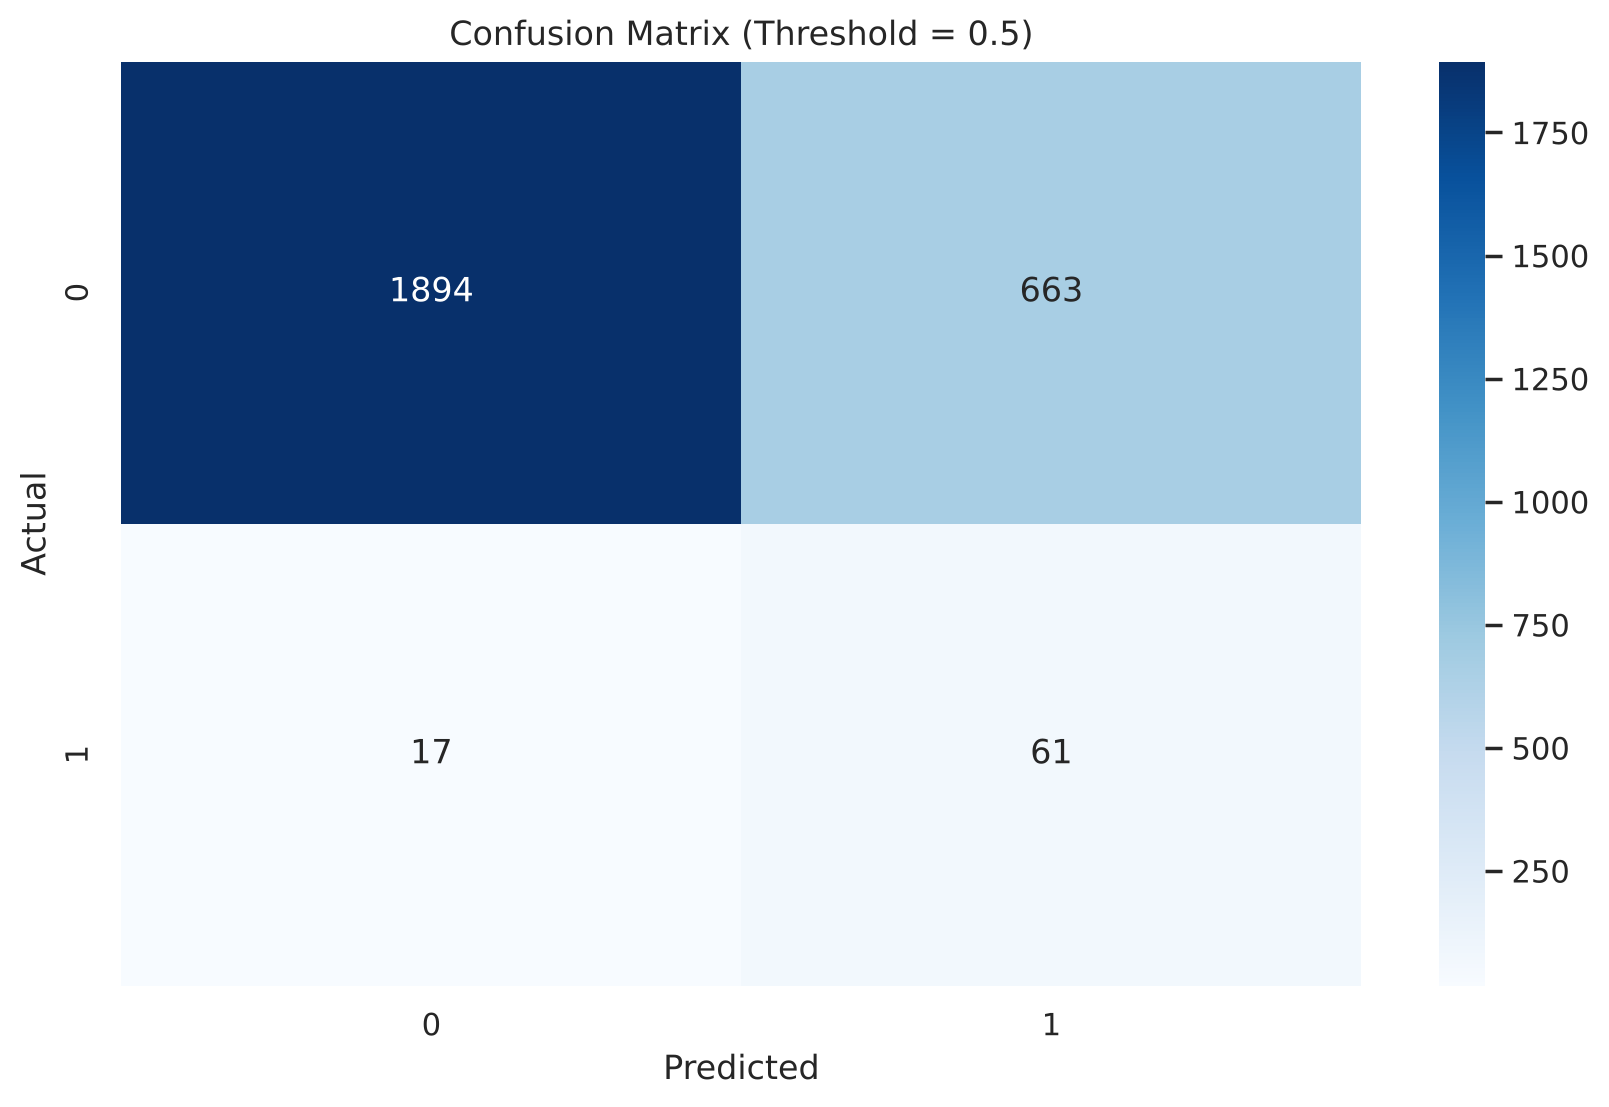


=== Logistic Regression Odds Ratios ===
                Feature  Coefficient  Odds_Ratio
20             Period_3     2.526512   12.509800
23             Period_6     1.496367    4.465435
24             Period_7     1.078453    2.940128
21             Period_4     0.946941    2.577811
1          noofpatients     0.785169    2.192778
14     DayofWeek_Sunday     0.644443    1.904926
40            Period_23     0.607166    1.835223
22             Period_5     0.590448    1.804796
2     noofinvestigation     0.535752    1.708734
19             Period_2     0.490466    1.633077
38            Period_21     0.458880    1.582301
5             HRG_VB04Z     0.452117    1.571635
18             Period_1     0.344044    1.410641
28            Period_11     0.175847    1.192255
0                   Age     0.122442    1.130253
12     DayofWeek_Monday     0.048909    1.050125
17  DayofWeek_Wednesday    -0.007412    0.992616
6             HRG_VB05Z    -0.032114    0.968396
16    DayofWeek_Tuesday    -

In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
# import scilit-learn modules for modeling and evaluation
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, recall_score

# ------------------------------
# 1. Load data and define variables
# ------------------------------
df = pd.read_csv("AED4weeks.csv")

#define the target variable and feature lists
target = 'Breachornot'
numeric_features = ['Age', 'noofpatients', 'noofinvestigation', 'nooftreatment']
categorical_features = ['HRG', 'DayofWeek', 'Period']

#separate feature x and y
X = df[numeric_features + categorical_features]
#map the target variable to binary value
y = df[target].map({'non-breach': 0, 'breach': 1})

# ------------------------------
# 2. Preprocessing
# ------------------------------
# Create a ColumnTransformer to apply different preprocessing to numeric and categorical data
preprocessor = ColumnTransformer(
    transformers=[
        ## Standardize numeric features (Scale to Mean=0, Std=1)
        ('num', StandardScaler(), numeric_features),
        # One-Hot Encode categorical features (Create dummy variables), dropping the first category to avoid multicollinearity
        ('cat', OneHotEncoder(drop='first'), categorical_features)
    ]
)
# Apply the transformations to the features
X_processed = preprocessor.fit_transform(X)

# ------------------------------
# 3. Train/Test Split 
# ------------------------------
## 'stratify=y' ensures the proportion of breaches (Class 1) is the same in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X_processed,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

# ------------------------------
# 4. Logistic Regression + CV
# ------------------------------
# Initialize Logistic Regression model
# class_weight='balanced' automatically adjusts weights inversely proportional to class frequencies
# This is crucial for imbalanced datasets (where breaches are rare)
logreg = LogisticRegression(
    max_iter=1000,
    class_weight='balanced'
)
# Define 5-Fold Stratified Cross-Validation to evaluate model stability
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
# Calculate average ROC-AUC score across 5 folds
roc_auc = cross_val_score(
    logreg, X_train, y_train, cv=cv, scoring='roc_auc'
).mean()
# Calculate average Recall score across 5 folds (Sensitivity)
recall = cross_val_score(
    logreg, X_train, y_train, cv=cv, scoring='recall'
).mean()

print(f"5-Fold CV ROC-AUC: {roc_auc:.3f}")
print(f"5-Fold CV Recall: {recall:.3f}")

# ------------------------------
# 5. Fit model on full training set
# ------------------------------
logreg.fit(X_train, y_train)

# ------------------------------
# 6. Prediction with threshold = 0.5
# ------------------------------
# Predict probabilities for the test set
y_prob = logreg.predict_proba(X_test)[:, 1]
# Convert probabilities to binary predictions using a 0.5 threshold
y_pred = (y_prob >= 0.5).astype(int)

print("\n=== Logistic Regression (Threshold = 0.5) ===")
print(classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix (Threshold = 0.5)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ------------------------------
# 7. Odds Ratios (Interpretability)
# ------------------------------
# Extract feature names generated by OneHotEncoder
ohe = preprocessor.named_transformers_['cat']
cat_feature_names = ohe.get_feature_names_out(categorical_features)
# Combine numeric and categorical feature names
all_features = numeric_features + list(cat_feature_names)
# Create a DataFrame to store coefficients and Odds Ratios
# Odds Ratio = exp(Coefficient). Values > 1 increase the likelihood of breach; < 1 decrease it.
coef_df = pd.DataFrame({
    'Feature': all_features,
    'Coefficient': logreg.coef_[0],
    'Odds_Ratio': np.exp(logreg.coef_[0])
})
# Sort by Odds Ratio to identify the most influential factors
coef_df = coef_df.sort_values(by='Odds_Ratio', ascending=False)

print("\n=== Logistic Regression Odds Ratios ===")
print(coef_df)
